# Interpolación Cuadrática

Estima valores intermedios entre datos conocidos ajustando un polinomio de segundo grado (parábola) a tres puntos ($x0$,$y0$), ($x1$,$y1$) y ($x2$,$y2$)
Suele ser más precisa que la interpolación lineal cuando los datos no siguen una línea recta.
Es más precisa especialmente en esos casos puesto que incorpora una curvatura que ayuda a mejorar la precisión cuando los datos no siguen una línea recta como en la interpolación lineal.

El objetivo es encontrar una función cuadrática $$ P(x)=a_0+a_1x+a_2x^2 $$ que pase por los tres puntos dados
- Hay que plantear el sistema, se empieza sustituyendo cada punto ($x1$,$y1$) en la ecuación cuadrática para obtener tres ecuaciones con tres incógnitas ($a_0$,$a_1$,$a_2$)
- Se resuelven los coeficientes, hay que encontrar los valores de las $a_n$ resolviendo el sistema o usando fórmulas equivalentes
- Evaluar el punto que buscas, sustituye el valor de $x$ deseado en $P(x)$ para obtener el estimado 

## Anotaciones
Después de ver un par de videos en los que se resuelven problemas de este estilo he notado que se usan sistemas de ecuaciones, lo cual añade un poco de complejidad al programa, la verdad no quiero programar el método de Gauss y sospecho que también necesito matemáticas simbólicas. <br>
Esto no debería ser un problema puesto que existe una solución bastante fácil y obvia que es usar una librería, reduce el código que escribo, el tiempo y lo hace más fácil. A cambio de no saber exactamente que hago. Por ello usaré la fórmula de *Lagrange* que es bastante más fácil de pasar a código, en este caso en vez de calcular las incógnitas solo calculas cada punto de la curva. 

$$
P(x) = \sum_{i=0}^{n} y_i \prod_{\substack{0 \le j \le n \\ j \neq i}} \frac{x - x_j}{x_i - x_j}
$$
Quedó peor para pasarla a código, usemos otra

$$
P_n(x) = y0 \frac{(x - x1)(x - x2)\cdots(x - x_n)}{(x0 - x1)(x0 - x2)\cdots(x0 - x_n)} + y1 \frac{(x - x0)(x - x2)\cdots(x - x_n)}{(x1 - x0)(x1 - x2)\cdots(x1 - x_n)} + \dots + y_n \frac{(x - x0)(x - x1)\cdots(x - x_{n-1})}{(x_n - x0)(x_n - x1)\cdots(x_n - x_{n-1})}
$$
Ahora sí, usaré solo 3 puntos porque eso es lo que generalmente piden. De cualquier forma puedes pasar al repositorio y probablemente la haga para `n` puntos

In [3]:
def interpolCuadratica(
        x,
        x0,
        x1,
        x2,
        y0,
        y1,
        y2
):
    L0 = ((A:=x-x1)*(x-x2))/((x0-x1)*(x0-x2))
    L1 = ((B:=x-x0)*(x-x2))/((x1-x0)*(x1-x2))
    L2 = ((B*A))/((x2-x0)*(x2-x1))
    return y0 * L0 + y1 * L1 + y2 * L2

Muy bien, probémoslo
|x|y|
|---|---|
|0|0|
|5|10|
|10|0|

In [4]:
interpolCuadratica(
    3, #y para x=3
    0,5,10, # x
    0,10,0 # y
)

8.4

Parece funcionar así que probemos el estándar con librerías, veamos qué tal funciona así

In [5]:
import numpy as np
xs, ys = [0, 5, 10], [0, 10, 0]
assert all(interpolCuadratica(xi, *xs, *ys) == yi for xi, yi in zip(xs, ys))
print(np.polyval(np.polyfit(xs, ys, 2), 3))  # debe dar 8.4

8.400000000000004


Quedó el 4 al final, probablemente por el `IEEE 754` pero aún así es correcto. Hay que tener cuidado con los floats y el `==` aquí funciona y está bien porque son datos enteros y es un ambiente ideal, no pasa nada.

Podemos ver la gráfica con `draw` de `personal`

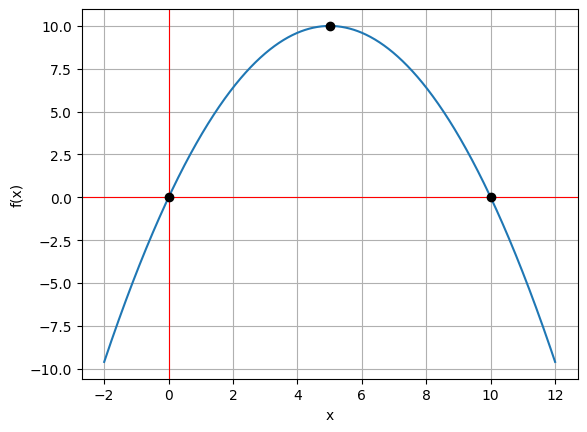

In [6]:
from personal import draw
xs, ys = [0, 5, 10], [0, 10, 0]
draw(lambda x: interpolCuadratica(x, *xs, *ys), -2, 12, nodos=(xs, ys))